# T1: Your first decision tree on nuclear data
### Predict the neutron capture cross section of gold-197 from the other isotopes, and compare it with the evaluated curve

**What you will do**

1. Read a small database of measured neutron capture cross sections and summarise it.
2. Train a decision tree on every isotope **except** gold-197.
3. Ask the tree for its prediction for gold-197 and plot it next to the EXFOR measurements and the ENDF/B-VII.1 evaluation.
4. Look inside the tree: the questions it asks, and which features it relies on.
5. Ask how honest this test is, and what question it answers.
6. Give the tree more features and see what changes (section 11).
7. Then **you** take over: tune the tree, and compare it with XGBoost and a random forest (section 12).

**The question behind it.** A model that has never seen gold-197 is given its charge (Z), its mass number (A) and a neutron energy.
Can it guess the cross section from what it learned about the other isotopes? This is the situation of an evaluator facing an isotope that nobody has measured.

*Vocabulary used below:* **feature** (an input to the model), **target** (what we predict), **training set** (what the model learns from), **hold-out** (data kept away from training to test the model),
**decision tree** (a model made of yes/no questions), **inference** (using a trained model to predict), **loss function** (the number the training tries to make small), **hyperparameter** (a setting we choose, not learned).

*To run it:* Python with `numpy`, `pandas`, `matplotlib` and `scikit-learn`. Section 12 also needs `xgboost` (`pip install xgboost`) and, if you want it, `optuna`.
Run the notebook from the `notebooks/` folder or from the repository root: it finds the two data files in `data/teaching/`.

## 1. Load the data
The table `capture_cleaned.csv` comes from EXFOR, the international library of measured nuclear data. Each row is **one measured point** of the reaction (n,$\gamma$):
a neutron is absorbed by a nucleus and a gamma ray is emitted. This reaction matters for reactors, for nuclear waste and for the origin of the heavy elements.
We look at **fast** neutrons, 0.1 to 20 MeV.

The file has been cleaned for you: plain cross sections only (no ratios, raw counts or other special data), no dataset or point that a statistical check flagged as inconsistent with the other measurements of the same reaction,
and at most 300 points per isotope so that no isotope dominates. The rules are in `scripts/build_au197_notebook_data.py`.

The second file is the **evaluated** curve of gold-197 from the ENDF/B-VII.1 library: an expert-made best estimate that combines measurements with nuclear theory. Gold-197 (n,$\gamma$) is one of the most carefully studied reactions in the field.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.tree import DecisionTreeRegressor, plot_tree

D = Path("../data/teaching") if Path("../data/teaching").exists() else Path("data/teaching")   # works from notebooks/ or from the repository root
db = pd.read_csv(D / "capture_cleaned.csv")        # one row per measured point
ev = pd.read_csv(D / "endf_Au197_capture.csv")     # the evaluated curve of gold-197
db.head()

,entry,Z,A,energy_eV,sigma_b
0,11235005,5,11,139000.0,0.000008
1,11235005,5,11,198000.0,0.000013
2,11235005,5,11,238000.0,0.000010
3,11235005,5,11,287000.0,0.000010
4,11235005,5,11,336000.0,0.000016


The columns are: `entry` (the EXFOR entry the point comes from, so every point can be traced to its paper), `Z` (protons), `A` (protons plus neutrons),
`energy_eV` (neutron energy in electron volts) and `sigma_b` (the cross section in barns; 1 barn = 10$^{-24}$ cm$^2$, roughly the area of a nucleus).

## 2. Summarise it

In [2]:
print(f"{len(db)} points from {db.entry.nunique()} EXFOR entries, for {db.groupby(['Z', 'A']).ngroups} isotopes")
print(f"neutron energies from {db.energy_eV.min() / 1e6:.1f} to {db.energy_eV.max() / 1e6:.0f} MeV")
print("points per isotope:")
print(db.groupby(["Z", "A"]).size().describe().round(0).to_string())

7624 points from 644 EXFOR entries, for 83 isotopes
neutron energies from 0.1 to 19 MeV
points per isotope:
count     83.0
mean      92.0
std       72.0
min       31.0
25%       45.0
50%       69.0
75%       98.0
max      300.0


Next, the reaction itself: all 83 isotopes in grey on logarithmic axes, gold-197 in red. In every isotope the cross section **falls with energy**, but the **level differs from one isotope to the next**.
The levels of the isotopes span about six orders of magnitude, so a model must use Z and A to know where on the page an isotope sits. Gold sits in the middle of a wide cloud.
How many isotopes really resemble gold is a question we will ask in section 10.

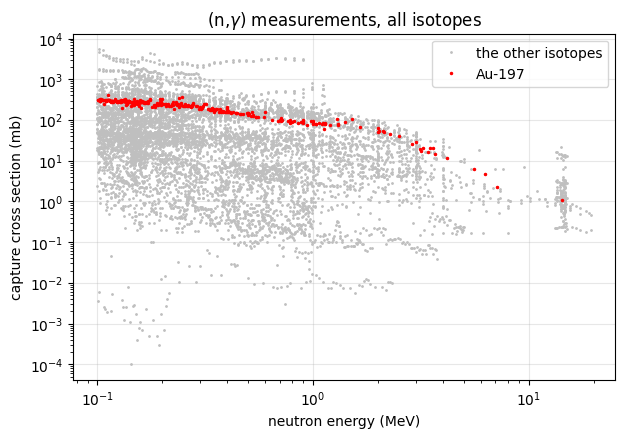

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(db.energy_eV / 1e6, db.sigma_b * 1000, ".", color="0.75", ms=2, label="the other isotopes")
gold = db[(db.Z == 79) & (db.A == 197)]
ax.plot(gold.energy_eV / 1e6, gold.sigma_b * 1000, ".", color="red", ms=3, label="Au-197")
ax.set(xscale="log", yscale="log", xlabel="neutron energy (MeV)", ylabel="capture cross section (mb)", title=r"(n,$\gamma$) measurements, all isotopes")
ax.legend(); ax.grid(alpha=0.3)

## 3. Prepare features and target
**Features:** Z, A and the neutron energy. **Target:** the cross section.

Cross sections and energies span many orders of magnitude, so we work with their **logarithms** (base 10). This is standard practice, for two reasons. A factor of 2 then means the same thing at every scale,
and the few very large cross sections do not dominate what the model learns. It also decides how we will measure error: as a **factor** (section 6).

In [11]:
db["logE"] = np.log10(db.energy_eV)            # log10 of the energy in eV
db["logS"] = np.log10(db.sigma_b * 1000)       # log10 of the cross section in millibarns
features = ["Z", "A", "logE"]

## 4. Hold out gold-197
We put **every** gold-197 point aside and train on all the other isotopes.

Why not a random 80/20 split of all points? Because neighbouring points of the same isotope are almost copies of each other. A random split would put some of the gold points in training and
test the model on the rest, so it would only have to *remember* gold. Holding out the whole isotope tests something harder: predicting an isotope the model has never seen. (Section 10 comes back to this.)

In [12]:
test = db[(db.Z == 79) & (db.A == 197)]       # gold-197: kept away from training
train = db.drop(test.index)                   # all other isotopes
print(f"training: {len(train)} points from {train.groupby(['Z', 'A']).ngroups} isotopes;  held out: {len(test)} points of Au-197")

training: 7324 points from 82 isotopes;  held out: 300 points of Au-197


## 5. Train a decision tree
A decision tree learns a list of yes/no questions about the features ("is Z above 28?", "is the energy above 1 MeV?"). Each question splits the training points into two groups.
At the end of a branch (a **leaf**) the tree predicts the average of the training points that landed there.

**The loss function.** The training has to decide *which* question to ask. It tries many candidates and keeps the one that makes the predictions best, and "best" needs a number: the **loss function**.
Here the loss is the **squared error on the log10 cross section** (`criterion="squared_error"`, scikit-learn's default for trees): the sum of (prediction $-$ measured value)$^2$ over the training points.

* *Why the log10?* A cross section is positive and spans six orders of magnitude (section 2). The loss on the log scale cares about the *ratio* between prediction and measurement, not the difference in millibarns, so a factor of 2 costs the same for a small cross section as for a large one.
  On the raw scale the model would only try to fit the biggest numbers.
* *Why squared?* It is smooth, it is what most textbooks start with, and with it the best prediction of a leaf is simply the **average** of its points. The price: a few wild points (and EXFOR has some) pull the average, because large errors are punished most.
  The alternative `criterion="absolute_error"` makes each leaf predict the **median** instead, which is more robust to wild points but slower to train. You can try it in section 12.

Two more settings control how detailed the tree gets: `max_depth` (the longest chain of questions) and `min_samples_leaf` (the smallest group allowed at a leaf). These are **hyperparameters**: we choose them, the model does not learn them.

In [13]:
tree = DecisionTreeRegressor(criterion="squared_error", max_depth=8, min_samples_leaf=5, random_state=0)
tree.fit(train[features], train.logS)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``m

## 6. Inference: predict gold-197
We now ask the tree for gold-197 at many energies. We build a table with Z = 79 and A = 197 on every row and a range of energies, and let the tree answer.
The range deliberately starts below the lowest measured energy and ends above the highest, to see what the tree does where it has little to go on.

In [16]:
E = np.logspace(4.5, 7.5, 400)                                   # 0.03 MeV to 30 MeV
grid = pd.DataFrame({"Z": 79, "A": 197, "logE": np.log10(E)})
prediction = 10 ** tree.predict(grid)                            # back from log10(mb) to mb

**How good is it? A note on units.** We want one yardstick for training, tuning and reporting. Training minimises the **mean squared error** (MSE) of log10 cross sections. We report its square root, the **root-mean-square error** (RMSE), converted back from log10 to a *factor*:
RMS factor = 10$^{	ext{RMSE}}$. A result of **1.0** would be perfect, **1.15** means the prediction is typically within about 15 % of the measurement, and **2.0** means it is typically off by a factor of 2.

Because squaring punishes large misses, a few wild points can dominate the RMS factor. So we also print the **median factor** (the median of the absolute log10 differences, converted back), which ignores wild points and shows what a *typical* point looks like.
When the two are close the errors are evenly spread; when the RMS factor is much bigger, a few points are very wrong. Both are useful, and the difference is information.

(Papers sometimes quote errors in **dex**, the raw log10 difference. A factor of 1.15 is 0.06 dex. We stay with factors in this notebook.)
We compare with the measurements, and with the evaluation, which is smoother than the individual measurements.

In [17]:
def errors(model, df, feats=features):
    # returns (RMS factor, median factor) of the model on df: the square root of the mean squared log10 error, and the median absolute log10 error, both converted back to factors
    r = model.predict(df[feats]) - df.logS
    return 10 ** np.sqrt(np.mean(r ** 2)), 10 ** np.median(np.abs(r))

rms, med = errors(tree, test)
print(f"against the EXFOR points of Au-197:  RMS factor {rms:.2f} (about {100 * (rms - 1):.0f} %),  median factor {med:.2f}")
lib = np.interp(test.logE, np.log10(ev.energy_eV), np.log10(ev.sigma_b * 1000))      # the evaluation at the energies of the points
print(f"against the ENDF/B-VII.1 evaluation: RMS factor {10 ** np.sqrt(np.mean((tree.predict(test[features]) - lib) ** 2)):.2f}")

against the EXFOR points of Au-197:  RMS factor 1.29 (about 29 %),  median factor 1.15
against the ENDF/B-VII.1 evaluation: RMS factor 1.27


## 7. Plot it with the measurements and the evaluation

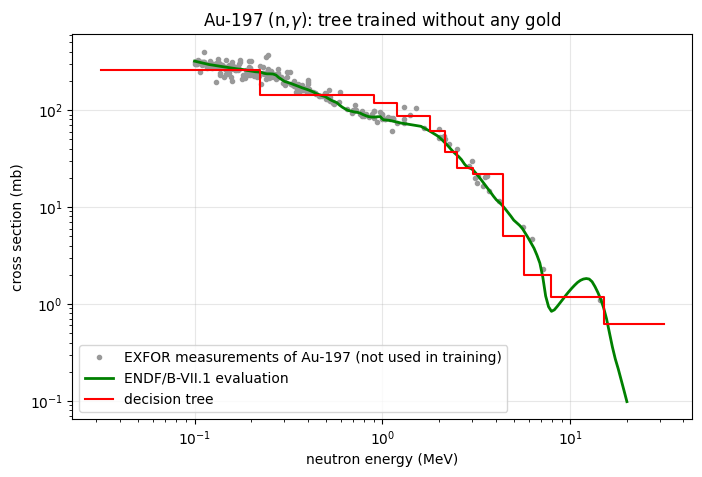

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(test.energy_eV / 1e6, test.sigma_b * 1000, ".", color="0.6", label="EXFOR measurements of Au-197 (not used in training)")
ax.plot(ev.energy_eV / 1e6, ev.sigma_b * 1000, "g-", lw=2, label="ENDF/B-VII.1 evaluation")
ax.plot(E / 1e6, prediction, "r-", drawstyle="steps-mid", label="decision tree")
ax.set(xscale="log", yscale="log", xlabel="neutron energy (MeV)", ylabel="cross section (mb)", title=r"Au-197 (n,$\gamma$): tree trained without any gold")
ax.legend(); ax.grid(alpha=0.3)

**What to notice**

* The tree's curve is made of **flat steps**. A tree can only predict one number per leaf, so it can never draw a smooth curve.
* It follows the fall of the cross section over two orders of magnitude using only what it learned from *other* isotopes.
* Where the steps are wide, the tree is a poor description of the smooth evaluation. Where measurements are plentiful in training, the steps are narrower.
* Beyond the range of the training data a tree **cannot extrapolate**: its answer is just the nearest leaf, a constant.
* The measurements of gold scatter around the evaluation. The evaluation is not the truth either: it is an expert's estimate, built from those same kinds of measurements.

## 8. Look inside the tree
The tree above is deep (up to 8 questions in a row), too big to read. Here is a small one with only 3 levels, trained the same way.
Each box shows the question, how many training points reached it, and the average log10 cross section of those points (`value`).

[Text(0.5, 0.875, 'Z <= 28.5\nsamples = 7324\nvalue = 1.327'),
 Text(0.25, 0.625, 'Z <= 9.5\nsamples = 2048\nvalue = 0.123'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'Z <= 6.5\nsamples = 278\nvalue = -0.799'),
 Text(0.0625, 0.125, 'samples = 42\nvalue = -1.967'),
 Text(0.1875, 0.125, 'samples = 236\nvalue = -0.592'),
 Text(0.375, 0.375, 'logE <= 5.907\nsamples = 1770\nvalue = 0.268'),
 Text(0.3125, 0.125, 'samples = 1359\nvalue = 0.416'),
 Text(0.4375, 0.125, 'samples = 411\nvalue = -0.222'),
 Text(0.75, 0.625, 'Z <= 61.0\nsamples = 5276\nvalue = 1.794'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'logE <= 6.005\nsamples = 2867\nvalue = 1.463'),
 Text(0.5625, 0.125, 'samples = 2290\nvalue = 1.613'),
 Text(0.6875, 0.125, 'samples = 577\nvalue = 0.87'),
 Text(0.875, 0.375, 'logE <= 6.333\nsamples = 2409\nvalue = 2.188'),
 Text(0.8125, 0.125, 'samples = 2234\nvalue = 2.287'),
 Text(0.9375, 0.125, 'samples = 175\nvalue = 0.934')]

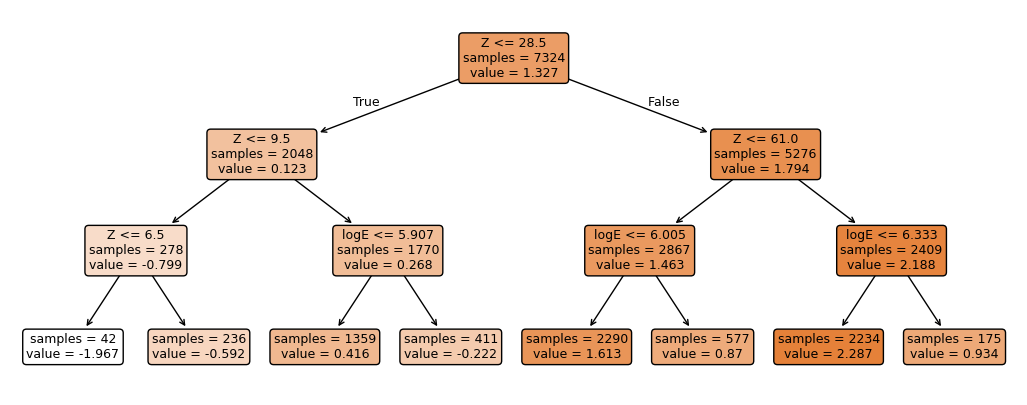

In [19]:
small = DecisionTreeRegressor(max_depth=3, random_state=0).fit(train[features], train.logS)
fig, ax = plt.subplots(figsize=(13, 5))
plot_tree(small, feature_names=features, filled=True, rounded=True, impurity=False, fontsize=9, ax=ax)

Read it from the top. The first questions are about the charge Z: they separate light, medium and heavy isotopes, whose cross sections sit at very different levels (the tree could also ask about A, which carries similar information). Questions about `logE` (the log10 of the energy in eV: `logE` = 6 means 1 MeV)
separate low from high energies. With so few questions the tree can only tell a handful of groups apart. Deeper trees add detail, and also add the risk of fitting noise.

## 9. Which features does the model rely on?
A tree can also tell us how much each feature contributed. The **feature importance** of scikit-learn adds up, for each feature, how much it reduced the loss over all the questions that used it, and scales the result so that the three numbers sum to 1.

A       0.094
logE    0.157
Z       0.749


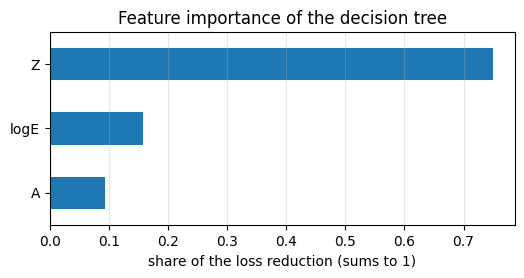

In [20]:
importance = pd.Series(tree.feature_importances_, index=features).sort_values()      # the tree of section 5 (depth 8)
ax = importance.plot.barh(figsize=(6, 2.5), color="tab:blue")
ax.set(xlabel="share of the loss reduction (sums to 1)", title="Feature importance of the decision tree"); ax.grid(alpha=0.3, axis="x")
print(importance.round(3).to_string())

Most of the work is done by **Z** and **A**: the tree spends its questions on telling isotopes apart, and only a smaller share on the energy dependence. That fits the picture of section 2, where the level of the curve is what differs most between isotopes.

Two cautions. Importance describes what the model used in *training*; it does not say what the physics depends on. And Z and A carry overlapping information (heavier nuclei have both more protons and a bigger A), so the tree can credit either one and the split between them is somewhat arbitrary.

## 10. How honest is this test?
We removed gold from training. If the long-term aim is to *evaluate* nuclear data with machine learning, why throw away measurements that exist?

We did not throw them away for good, only for this test. The right test depends on the question, and here are two ways to ask it.
The tree below has **no limits** on its depth (`max_depth=None`, `min_samples_leaf=1`), so it is free to memorise.

In [21]:
def held_out_factor(train_df, test_df, **settings):
    m = DecisionTreeRegressor(random_state=0, **settings).fit(train_df[features], train_df.logS)
    return errors(m, test_df)[0]                       # the RMS factor

half = test.sample(frac=0.5, random_state=0)           # half of the gold points
print(f"gold absent from training:                          RMS factor {held_out_factor(train, test):.2f}")
print(f"half of the gold in training, other half scored:    RMS factor {held_out_factor(pd.concat([train, half]), test.drop(half.index)):.2f}")

gold absent from training:                          RMS factor 1.71
half of the gold in training, other half scored:    RMS factor 1.24


Both numbers are correct, and they answer different questions.

* **Gold absent** asks: *how well can the model do for an isotope with no data at all?* That is the situation for unstable or exotic isotopes that nobody has measured, and for any new reaction.
  It is the hardest case and a deliberately pessimistic one: for gold we do have data.
* **Half of the gold present** asks: *how well can the model fill the gaps of an isotope that has been measured?* This is much easier, because the model can lean on gold's own neighbouring points.
  But a random split like this mostly measures **memorisation**: the points of one measurement campaign are almost copies of each other, so the score looks excellent whether or not the model has learned anything about physics.
  A fairer version holds out whole experiments (EXFOR entries) or later years, as the real-world question "would a *new* measurement agree with the model?" requires.

For a real evaluation of gold you would of course keep all its data and use the model as a guide for the gaps and for the energies where nothing has been measured. The model is then only as good as the data:
EXFOR contains errors and disagreements, which is why the data were cleaned first. The honest habit is to **decide first which situation your model will face, then build the test to match**, and to say which test you used.

### Is gold special? The look-alikes
There is a second, quieter way to be flattered by a test: if the training set already contains isotopes that look almost exactly like the one we predict, the model only has to copy them.
Below we measure, for every other isotope, how far its curve is from gold's (the typical difference in log10 cross section, in energy bins of 0.125 dex), and count those within a factor of 2 (0.3 in log10).

In [22]:
bins = np.floor(db.logE * 8)                                                    # energy bins
curve = db.groupby([db.Z, db.A, bins]).logS.median().unstack([0, 1])           # one column per isotope: its curve
shared = curve.notna().mul(curve[(79, 197)].notna(), axis=0).sum()             # energy bins that an isotope shares with gold
distance = curve.sub(curve[(79, 197)], axis=0).abs().median()[shared >= 4].drop((79, 197))
look_alikes = distance[distance < 0.3].index
print(f"{len(look_alikes)} of the {len(distance)} comparable isotopes lie within a factor of 2 of gold; the median isotope is off by a factor of {10 ** distance.median():.1f}")
train_hard = train[~train.set_index(["Z", "A"]).index.isin(look_alikes)]
print(f"tree of section 5, trained without the look-alikes: RMS factor {held_out_factor(train_hard, test, max_depth=8, min_samples_leaf=5):.2f}  (with them: {rms:.2f})")

24 of the 76 comparable isotopes lie within a factor of 2 of gold; the median isotope is off by a factor of 3.6
tree of section 5, trained without the look-alikes: RMS factor 4.04  (with them: 1.29)


Only a minority of the isotopes resemble gold (almost all of them are heavy: for example rhodium, silver, tantalum, iridium, uranium and plutonium), but they carry the prediction: without them the RMS factor grows from about 1.3 to about 4.
So a good score on gold says less about "machine learning predicts unmeasured isotopes" than it seems. It says that **gold has neighbours that are almost copies of it**.
A harder and more honest test picks a target with few look-alikes, or removes whole regions of the chart of nuclides from training, for example every isotope with Z above 60.

## 11. More features: does the tree do better with ten?
So far the tree knew only three things about gold: its charge Z, its mass number A and the neutron energy. Physicists know much more about a nucleus. Here are seven more properties of each isotope, computed from the AME2020 table of measured nuclear masses (`isotope_features.csv`):

| feature | meaning |
|---|---|
| `N` | number of neutrons, A $-$ Z |
| `Q_capture` | energy released when the target captures a neutron (MeV): the excitation energy of the nucleus that is formed |
| `S_n` | energy needed to pull one neutron out of the target (MeV) |
| `B_per_A` | binding energy per nucleon (MeV): how tightly the nucleus is held together |
| `Z_odd`, `N_odd` | 1 if the number of protons (neutrons) is odd, else 0: pairing makes even and odd nuclei behave differently |
| `N_magic_dist` | how far N is from the nearest "magic number" (2, 8, 20, 28, 50, 82, 126), where nuclei are especially stable |

Together with Z, A and `logE` that makes **ten features**. We repeat sections 4 to 10 with them: the same tree settings, the same gold held out, the same look-alikes. Two questions: **do the predictions improve**, and **does the tree still depend on the look-alikes?**

In [23]:
db10 = db.merge(pd.read_csv(D / "isotope_features.csv"), on=["Z", "A"])        # add the seven properties to every measured point
features10 = features + ["N", "Q_capture", "S_n", "B_per_A", "Z_odd", "N_odd", "N_magic_dist"]
test10 = db10[(db10.Z == 79) & (db10.A == 197)]
train10 = db10.drop(test10.index)
hard10 = train10[~train10.set_index(["Z", "A"]).index.isin(look_alikes)]       # without the look-alikes of section 10

def fit_and_score(feats):
    fit = lambda df: DecisionTreeRegressor(criterion="squared_error", max_depth=8, min_samples_leaf=5, random_state=0).fit(df[feats], df.logS)
    model = fit(train10)
    return model, errors(model, test10, feats), errors(fit(hard10), test10, feats)[0]

model3, (rms3, med3), hard3 = fit_and_score(features)
model10, (rms10, med10), hard10_rms = fit_and_score(features10)
print("               RMS factor   median factor   RMS factor without the look-alikes")
print(f"3 features:    {rms3:9.2f}   {med3:13.2f}   {hard3:30.2f}")
print(f"10 features:   {rms10:9.2f}   {med10:13.2f}   {hard10_rms:30.2f}")

               RMS factor   median factor   RMS factor without the look-alikes
3 features:         1.29            1.15                             4.04
10 features:        1.40            1.18                            14.95


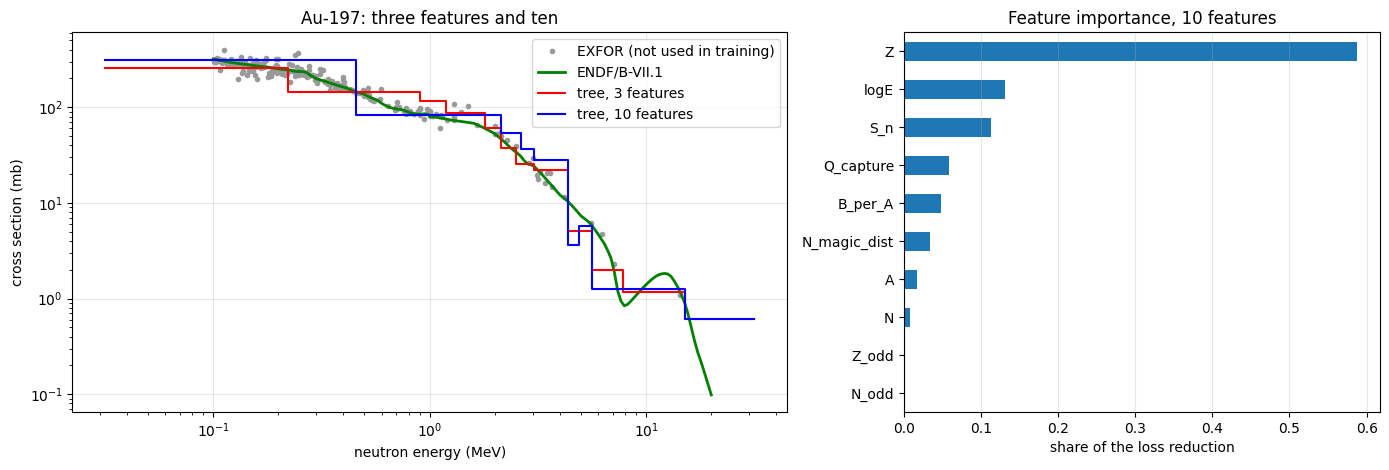

In [24]:
grid10 = test10[features10].iloc[[0] * len(E)].reset_index(drop=True)             # gold's ten properties repeated on every row
grid10["logE"] = np.log10(E)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [3, 2]})
ax[0].plot(test.energy_eV / 1e6, test.sigma_b * 1000, ".", color="0.6", label="EXFOR (not used in training)")
ax[0].plot(ev.energy_eV / 1e6, ev.sigma_b * 1000, "g-", lw=2, label="ENDF/B-VII.1")
ax[0].plot(E / 1e6, prediction, "r-", drawstyle="steps-mid", label="tree, 3 features")
ax[0].plot(E / 1e6, 10 ** model10.predict(grid10[features10]), "b-", drawstyle="steps-mid", label="tree, 10 features")
ax[0].set(xscale="log", yscale="log", xlabel="neutron energy (MeV)", ylabel="cross section (mb)", title="Au-197: three features and ten"); ax[0].legend(); ax[0].grid(alpha=0.3)
pd.Series(model10.feature_importances_, index=features10).sort_values().plot.barh(ax=ax[1], color="tab:blue")
ax[1].set(xlabel="share of the loss reduction", title="Feature importance, 10 features"); ax[1].grid(alpha=0.3, axis="x")
plt.tight_layout()

**Is gold typical?** One isotope is a small sample. We repeat the comparison, holding out in turn every isotope that has at least 100 measured points (the tree is the same, only the held-out isotope changes).

In [25]:
def loo_rms(feats, Z, A):
    t = db10[(db10.Z == Z) & (db10.A == A)]
    m = DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=0).fit(db10.drop(t.index)[feats], db10.drop(t.index).logS)
    return errors(m, t, feats)[0]

big = db10.groupby(["Z", "A"]).size().loc[lambda n: n >= 100].index
table = pd.DataFrame([(Z, A, loo_rms(features, Z, A), loo_rms(features10, Z, A)) for Z, A in big], columns=["Z", "A", "3 features", "10 features"])
print(f"{len(table)} isotopes. Geometric mean of the RMS factor:  3 features {np.exp(np.log(table['3 features']).mean()):.2f},  10 features {np.exp(np.log(table['10 features']).mean()):.2f}")
print(f"the 10-feature tree is better on {(table['10 features'] < table['3 features']).sum()} of {len(table)} isotopes")

20 isotopes. Geometric mean of the RMS factor:  3 features 3.52,  10 features 3.08
the 10-feature tree is better on 10 of 20 isotopes


**What to take from it**

* **For gold, nothing improved.** The prediction is about as good as before (slightly worse by the RMS factor), and the curves look alike. Over all the isotopes the extra features help a little on average, but not on every isotope.
* **The dependence on look-alikes did not go away.** Without them the error is still large, and for gold it is no better than with three features. More features did not teach the tree physics that carries over to an isotope with no neighbours.
* **Why?** All seven new features are properties of the *isotope*: they are the same for every point of an isotope. The tree has only 82 training isotopes, not 7,000 independent examples. With many isotope-level features it has more ways to tell isotopes apart and remember them,
  which is memorisation again, one level up. A feature helps only if its relation to the cross section is something the tree can learn from 82 examples.
* **Importance moves around.** A, which carried about a fifth of the weight before, is now almost unused: `S_n`, `Q_capture` and `B_per_A`, which are smooth functions of Z and A and carry much of the same information, took its place. The importance of a feature depends on which other features are present.
  (The parity flags barely matter here.)
* **Physics can still help.** Good features are the ones a physicist would expect to matter, for example the energy released by the capture. But a tree that has to find that out from 82 isotopes may not, and other models may use the features better. That is a question for XGBoost and the random forest in section 12.

## 12. Your turn
Everything above used one model (a decision tree), one setting of its hyperparameters and one held-out isotope. These exercises change that. Work in a new copy of the notebook, and report errors as factors (RMS and median, as in section 6).

### A. Hyperparameters (warm-up)
1. Change `max_depth` to 2, 4, 12 and `None` (no limit), and `min_samples_leaf` to 1 and 50, and re-run from section 5. Plot the RMS factor and the median factor against the depth. How do the error and the shape of the curve change? Is the error a smooth function of the depth?
   One held-out isotope is a small sample: do not over-read it.
2. Change the loss: `criterion="absolute_error"`. What changes in the curve, and in the time the training takes?
3. Hold out another isotope, for example `(92, 238)` for uranium-238 or `(73, 181)` for tantalum-181. Is gold easier or harder than the others?

### B. Choose the hyperparameters by optimisation
Picking `max_depth` and `min_samples_leaf` by eye is not a method. Implement a **simple hyperparameter optimisation** that picks them for you.
You could use a grid search or a random search from `scikit-learn` (`GridSearchCV`, `RandomizedSearchCV`), or a dedicated tool such as `optuna` if you want something more adaptive. Keep it small: a few dozen trials is enough.

The important design question: **how do you score each trial?** If the validation points come from isotopes that the model also trained on, you are back to the random split of section 4 and the optimiser will favour a model that memorises.
Make the validation hold out *whole isotopes*, for example with `GroupKFold` and the isotope (Z, A) as the group, and score the trials with the same yardstick as the training loss (`scoring="neg_mean_squared_error"` in scikit-learn).

Then answer: which settings did it choose, and does the held-out gold error improve over the settings we chose by hand? How does the score of the optimiser (its cross-validation error) compare with the error on gold, and why might they differ?

### C. The main task: compare three models
Implement **XGBoost** (`xgboost.XGBRegressor`) and a **random forest** (`sklearn.ensemble.RandomForestRegressor`) with the same features, the same training set and the same held-out gold as the tree, and compare **the three models**.
Tune each one with your optimiser from part B (each has its own hyperparameters: for example the number of trees, the depth and the learning rate for XGBoost).

Report, in one table and one figure:

* the RMS factor and the median factor on gold, for the default settings and after tuning;
* the three predictions plotted against the EXFOR points and the ENDF evaluation, as in section 7;
* the time to train each model, and the feature importances of each (as in section 9: do they agree with the tree?).

Then discuss: which model is best, and by how much? Is the difference bigger than the scatter you get from one held-out isotope to the next? To find out, repeat the comparison for five or more other held-out isotopes and compare the averages.
Which curve would you trust more as an evaluator, and why? What does a more complex model cost you (time, readability), and what does it buy?

### D. If you have time
Give XGBoost and the random forest the ten features of section 11. Do they use them better than the tree did? Use the look-alike test of section 10 on your best model: does it depend on the look-alikes as much as the tree? Which of the seven new features does each model find important?

## Where the data come from
* **EXFOR**: the experimental nuclear reaction data library (IAEA Nuclear Data Section and partner centres), read through the X4Pro database (content of November 2025).
* **ENDF/B-VII.1**: the evaluated nuclear data library of the United States (Chadwick et al., Nuclear Data Sheets 112, 2011).